# 03 · Exploring the Training Rows and Preparing Model Inputs

**The question:** What patterns separate the classes in the training rows, and how should we turn the raw columns into clean model inputs?

| | |
|---|---|
| **Input** | The raw training file and the roles from Notebook 02 (`data/processed/v3/02_roles.csv`) |
| **What we do** | Explore how each feature differs between classes (using `train` rows only), then build two preprocessing versions |
| **Output** | Fitted preprocessing pipelines (`models/v3/`), model-ready matrices for all three roles (`data/processed/v3/`), figures and tables |

**Important rule for this notebook:** everything is learned from the **`train` role only** (140,273 rows). `model_selection` and `calibration`
rows are only *transformed*, never used to decide anything. The test file is not opened at all.

## 1. Setup and load the train rows

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler

from src.notebook_helpers import (ROOT, TRAIN_CSV, RAW_SHA256, TARGETS, CATEGORICAL, CLASSES, ROLES, DATA, MODELS,
                                  sha256, save_table, save_figure, save_json, read_json, setup_style)
setup_style()

assert sha256(TRAIN_CSV) == RAW_SHA256['train']
raw = pd.read_csv(TRAIN_CSV, low_memory=False)
roles = pd.read_csv(DATA / '02_roles.csv')
assert sha256(DATA / '02_roles.csv') == read_json(DATA / '02_manifest.json')['roles_sha256']
assert (roles.source_id.to_numpy() == raw.id.to_numpy()).all()

predictors = [c for c in raw.columns if c not in TARGETS]
numeric = [c for c in predictors if c not in CATEGORICAL]
raw['role'] = roles.role.to_numpy()
fit = raw[raw.role == 'train']
print(f'train rows: {len(fit):,}  (out of {len(raw):,} in the training file)')

train rows: 140,273  (out of 175,341 in the training file)


## 2. Class balance in the train rows

A quick reminder of what we are working with.

In [2]:
balance = fit.attack_cat.value_counts().reindex(CLASSES).to_frame('rows')
balance['%'] = balance.rows / len(fit) * 100
display(balance.sort_values('rows', ascending=False).T)

attack_cat,Normal,Generic,Exploits,Fuzzers,DoS,Reconnaissance,Analysis,Backdoor,Shellcode,Worms
rows,"44,800.0000","32,000.0000","26,714.0000","14,547.0000","9,811.0000","8,393.0000","1,600.0000","1,397.0000",907.0000,104.0000
%,31.9377,22.8127,19.0443,10.3705,6.9942,5.9833,1.1406,0.9959,0.6466,0.0741


## 3. Which features differ between classes?

For each class we take the **median** of every number column (on a log scale, because the columns are skewed) and then
compare classes column by column. Dark red means "high for this class compared with the other classes", dark blue means "low".
This one picture shows which measurements carry class information.

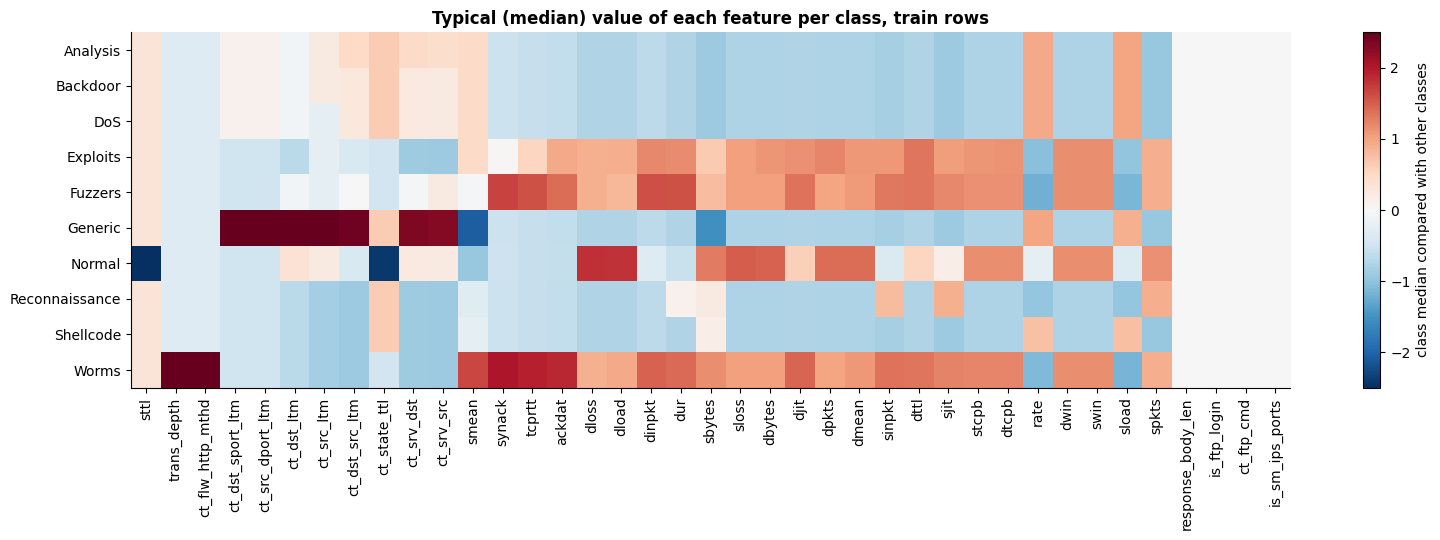

In [3]:
log_fit = np.log1p(fit[numeric])
medians = log_fit.groupby(fit.attack_cat).median().reindex(CLASSES)
spread = medians.std().replace(0, np.nan)
z = ((medians - medians.mean()) / spread).fillna(0)
order = z.abs().max().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(16, 5.5))
im = ax.imshow(z[order], cmap='RdBu_r', vmin=-2.5, vmax=2.5, aspect='auto')
ax.set_xticks(range(len(order)), order, rotation=90); ax.set_yticks(range(10), CLASSES); ax.grid(False)
fig.colorbar(im, ax=ax, label='class median compared with other classes')
ax.set_title('Typical (median) value of each feature per class, train rows')
plt.tight_layout(); save_figure(fig, '03_class_medians_heatmap'); plt.show()

**What we see:**

- **Normal** traffic stands out: low TTL values (`sttl`, `ct_state_ttl`) and much more data coming back (`dbytes`, `dload`, `dloss`).
- **Generic** has its own clear profile: very high "recent flows" counters (many similar connections) and small packets (`smean`).
- **Worms** is the only class with high HTTP columns (`trans_depth`, `ct_flw_http_mthd`). **Fuzzers** and **Exploits** look like longer, two-way TCP conversations.
- **Analysis, Backdoor and DoS** have almost identical rows of colour. The measurements make them look alike,
  which matches the conflicts we found in Notebook 02. Expect a model to mix these classes up.

## 4. A closer look at six features

Box plots show the spread of each feature per class (log scale). The box holds the middle half of the rows; the line inside is the median.

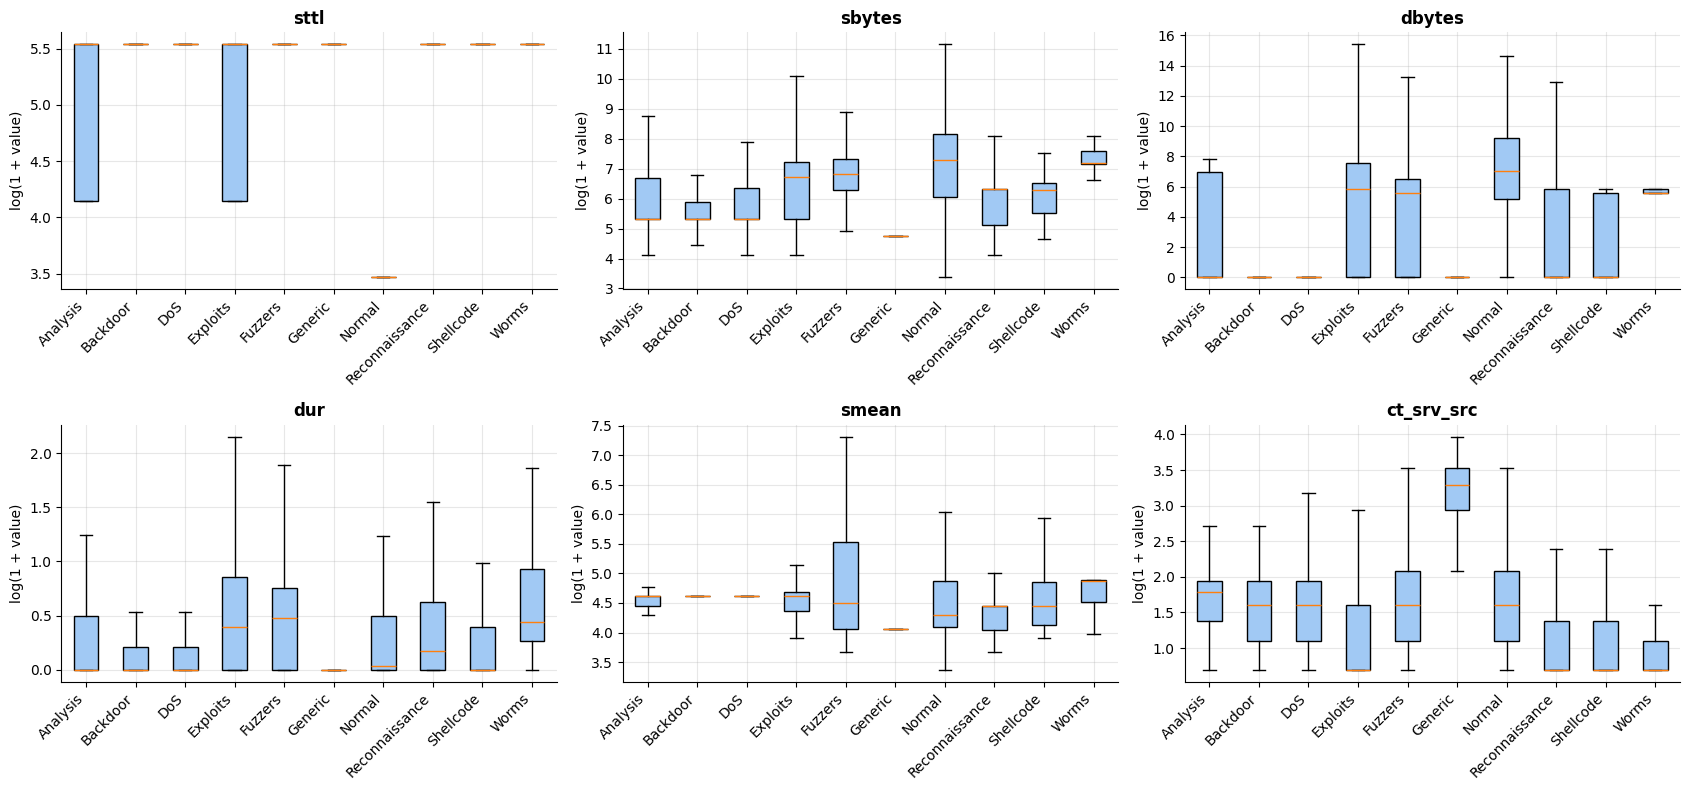

In [4]:
six = ['sttl', 'sbytes', 'dbytes', 'dur', 'smean', 'ct_srv_src']
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.ravel(), six):
    data = [np.log1p(fit.loc[fit.attack_cat == c, col]) for c in CLASSES]
    ax.boxplot(data, showfliers=False, patch_artist=True, boxprops=dict(facecolor='#A1C9F4'))
    ax.set_xticks(range(1, 11), CLASSES, rotation=45, ha='right')
    ax.set(title=col, ylabel='log(1 + value)')
plt.tight_layout(); save_figure(fig, '03_six_features_by_class'); plt.show()

In [5]:
ttl = pd.crosstab(fit.sttl, fit.attack_cat, normalize='columns').reindex(columns=CLASSES) * 100
display(ttl[ttl.max(axis=1) > 1].round(1))

attack_cat,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
sttl,,,,,,,,,,
0,0.1000,0.8000,0.5000,0.5000,0.1000,0.0000,5.1000,0.2000,0.0000,0.0000
31,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,70.7000,0.0000,0.0000,0.0000
62,27.6000,2.3000,10.2000,40.0000,0.3000,0.6000,3.8000,0.3000,0.0000,3.8000
254,72.3000,96.9000,89.2000,59.6000,99.6000,99.4000,19.8000,99.5000,100.0000,96.2000


**What we see:**

- `sttl` (time-to-live) is a very strong separator: 71% of Normal flows have 31, while most attack flows have 254.
  Only Exploits and Analysis often use 62. TTL depends on the machines
  used in the testbed, so this is a strong signal **in this dataset**, but it may not carry over to other networks. We keep it, and remember it.
- `sbytes`, `dbytes` and `smean` separate Normal and Fuzzers from Generic, but overlap for Analysis, Backdoor, DoS and Exploits.
- Most Generic, Analysis, Backdoor and DoS flows have `dbytes = 0`: the other side sent no data back at all (only 12% of Normal flows do).

## 5. Text columns and classes

Do protocol, service and state differ between classes? Each bar shows how a class is spread over the most common values.

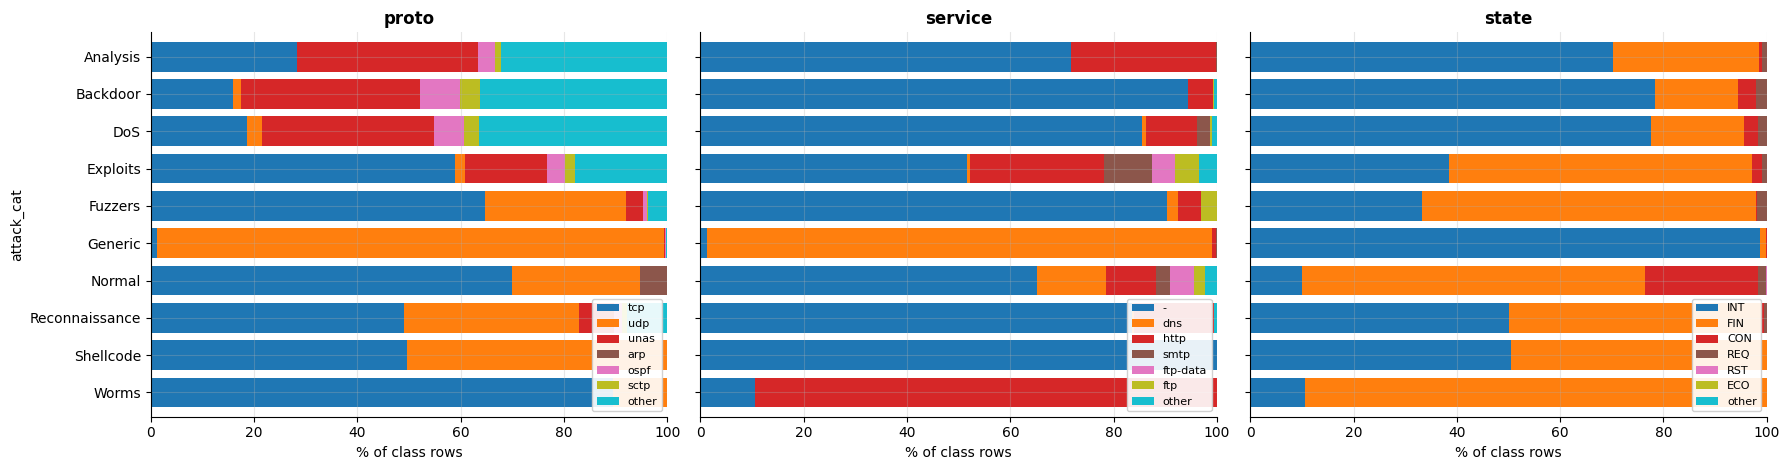

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, col in zip(axes, CATEGORICAL):
    top = fit[col].value_counts().head(6).index
    values = fit[col].where(fit[col].isin(top), 'other')
    table = pd.crosstab(fit.attack_cat, values, normalize='index').reindex(CLASSES) * 100
    table[list(top) + ['other']].plot.barh(stacked=True, ax=ax, width=0.8, colormap='tab10', legend=False)
    ax.set(title=col, xlabel='% of class rows'); ax.legend(fontsize=8, loc='lower right', framealpha=0.9)
axes[0].invert_yaxis()
plt.tight_layout(); save_figure(fig, '03_text_columns_by_class'); plt.show()

**What we see:**

- **Normal** is mostly `tcp` (70%) ending in state `FIN` (66%).
- **Generic** is almost entirely `udp` + `dns` + state `INT` (98-99%).
- **Analysis, Backdoor and DoS** use the unusual protocol `unas` about a third of the time, mostly have `service = '-'` and end in state `INT`.
- **Worms** is mostly `tcp` + `http` + `FIN` (89%).

The text columns clearly carry class information and must be kept.

## 6. Which number columns move together?

Two columns that rise and fall together carry overlapping information. We use **Spearman correlation**, which works well for skewed data
(it compares rankings, not raw sizes).

,column A,column B,spearman
1321,is_ftp_login,ct_ftp_cmd,1.0000
1010,trans_depth,ct_flw_http_mthd,0.9996
801,tcprtt,synack,0.9968
802,tcprtt,ackdat,0.9937
643,swin,dwin,0.9905
82,dpkts,dbytes,0.9897
841,synack,ackdat,0.9844
180,dbytes,dmean,0.9627
375,dload,dmean,0.9623
203,rate,sload,0.9605


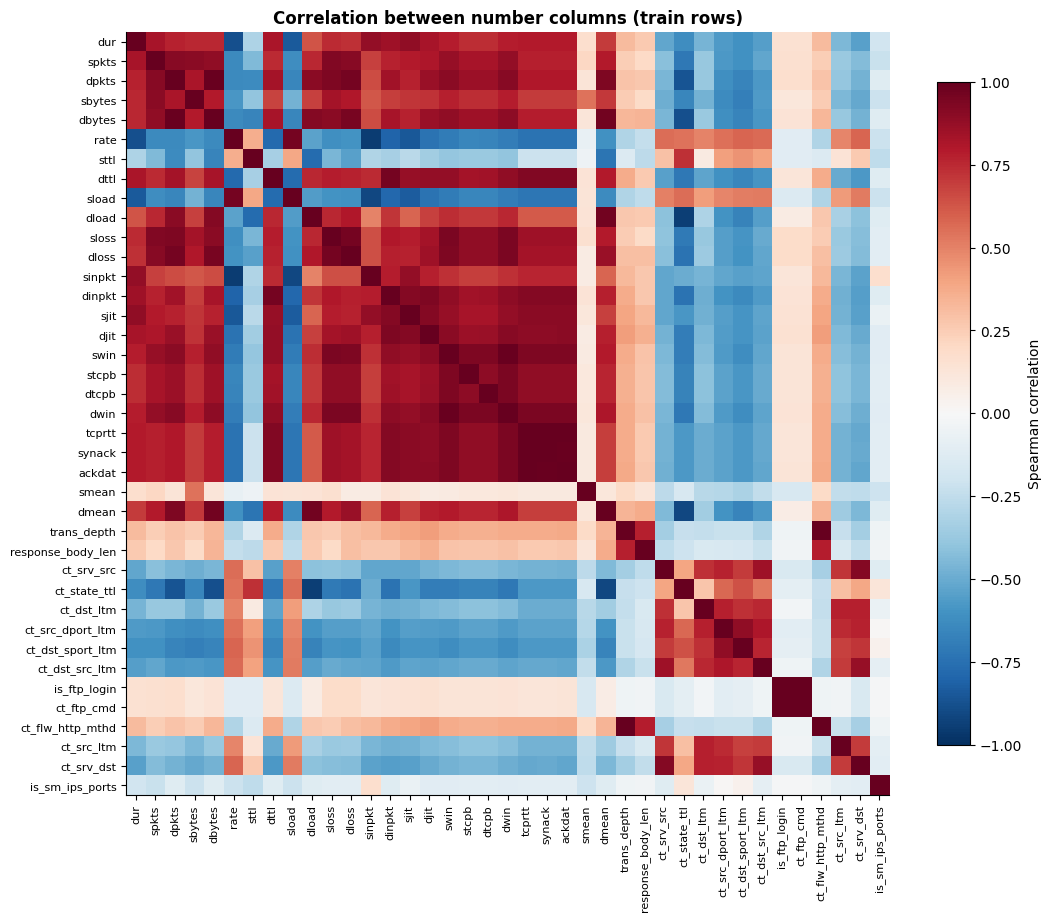

In [7]:
corr = fit[numeric].corr(method='spearman')
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('spearman').reset_index().rename(columns={'level_0': 'column A', 'level_1': 'column B'}))
strong = pairs[pairs.spearman.abs() >= 0.9].sort_values('spearman', key=abs, ascending=False)
save_table(strong, '03_strong_correlations')
display(strong)

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric)), numeric, rotation=90, fontsize=8); ax.set_yticks(range(len(numeric)), numeric, fontsize=8); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='Spearman correlation')
ax.set_title('Correlation between number columns (train rows)')
plt.tight_layout(); save_figure(fig, '03_correlation_heatmap'); plt.show()

**What we see:** Several groups of columns are strongly related, for example the packet and byte counts, the TCP timing trio
(`tcprtt`, `synack`, `ackdat`), and some "recent flows" counters. `is_ftp_login` and `ct_ftp_cmd` are exact copies in the training file.
Overlapping information is not a problem for tree models, and we do **not** drop columns here; Notebook 05 decides that with care.

## 7. Why some columns need a log transform

Linear models and neural networks are sensitive to scale. When a column ranges from 0 to 12 million, a few huge values dominate everything.
Two simple steps fix this:

1. **log(1 + x)** squeezes huge values together while keeping zeros at zero and keeping the order of values.
2. **Robust scaling** centres each column on its median and divides by its interquartile range, so outliers have little influence on the scaling itself.

A worked example with five byte counts:

In [8]:
example = pd.DataFrame({'bytes': [0, 10, 100, 1_000, 10_000_000]})
example['log(1 + bytes)'] = np.log1p(example.bytes)
median, iqr = example['log(1 + bytes)'].median(), example['log(1 + bytes)'].quantile(0.75) - example['log(1 + bytes)'].quantile(0.25)
example['after robust scaling'] = (example['log(1 + bytes)'] - median) / iqr
display(example)

,bytes,log(1 + bytes),after robust scaling
0,0,0.0000,-1.0231
1,10,2.3979,-0.4915
2,100,4.6151,0.0000
3,1000,6.9088,0.5085
4,10000000,16.1181,2.5501


The raw values go from 0 to 10 million; after the two steps they go from about -1.0 to 2.6, and their order is unchanged.

Below: the same idea on real columns of the train rows.

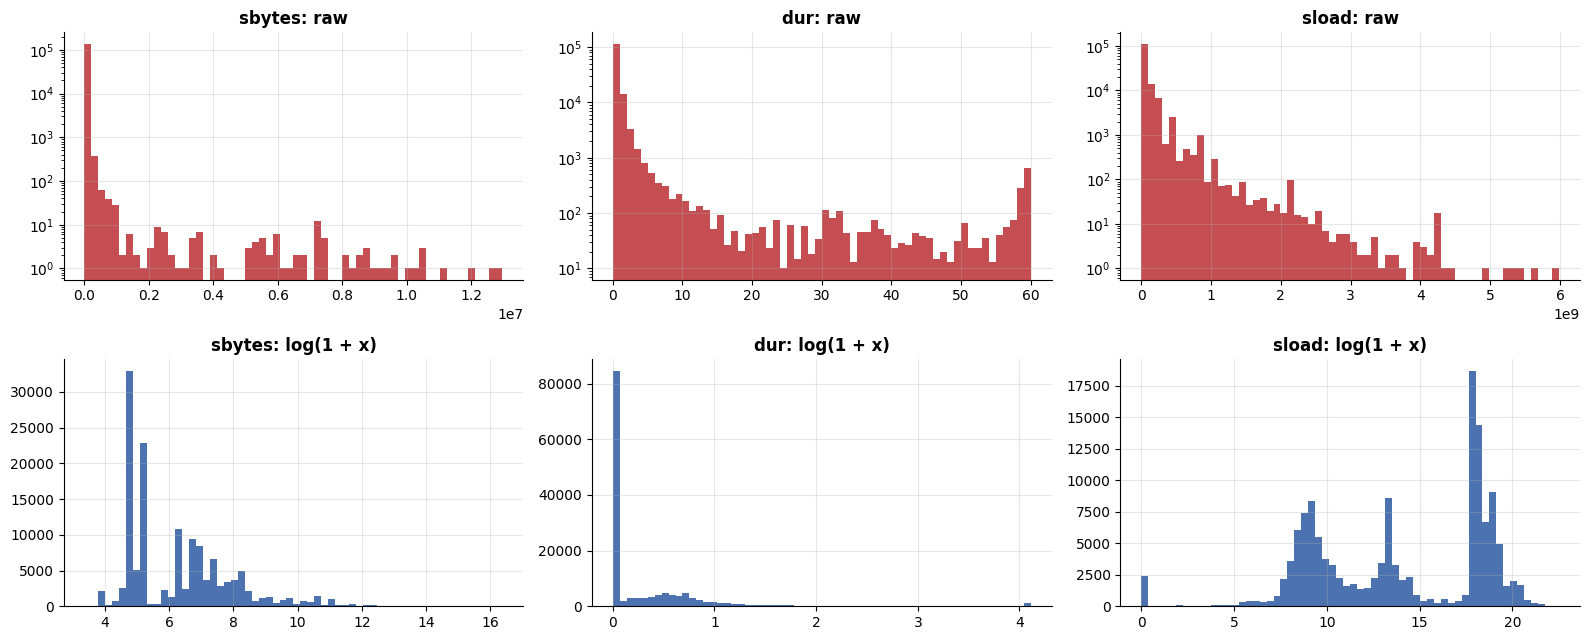

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5))
for i, col in enumerate(['sbytes', 'dur', 'sload']):
    axes[0, i].hist(fit[col], bins=60, color='#C44E52'); axes[0, i].set(title=f'{col}: raw', yscale='log')
    axes[1, i].hist(np.log1p(fit[col]), bins=60, color='#4C72B0'); axes[1, i].set(title=f'{col}: log(1 + x)')
plt.tight_layout(); save_figure(fig, '03_log_before_after'); plt.show()

## 8. The two input versions

Different models need different inputs, so we prepare **two versions** of the same data:

| Version | Number columns | Text columns | For which models |
|---|---|---|---|
| **Tree version** | unchanged | one-hot encoded | Decision tree, LightGBM. Trees split on thresholds, so scale does not matter |
| **Scaled version** | log(1 + x) for 13 heavy-tailed size and timing columns, then robust scaling for all | one-hot encoded | Logistic regression, neural networks |

**One-hot encoding** turns a text column into yes/no columns, e.g. `proto = tcp` becomes `proto_tcp = 1` and all other `proto_... = 0`.
A value that never appeared in the train rows simply gets all zeros (`handle_unknown='ignore'`), so new values such as the test-only states cannot break anything.

The 13 log columns are the heavy-tailed byte, packet, load, loss and packet-gap measurements. TCP handshake times (`synack`, `ackdat`),
small whole-number counters and flags (`trans_depth`, `ct_*`, `is_ftp_login`) are only robust-scaled. These choices were fixed in the earlier project version
and we keep them unchanged so all results stay comparable.

In [10]:
LOG_COLUMNS = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'sload', 'sloss', 'dloss',
               'sinpkt', 'dinpkt', 'sjit', 'djit', 'response_body_len']
PLAIN_COLUMNS = [c for c in numeric if c not in LOG_COLUMNS]

skew_table = fit[numeric].skew().rename('skewness (train rows)').to_frame()
skew_table['treatment in scaled version'] = np.where(skew_table.index.isin(LOG_COLUMNS), 'log + robust scale', 'robust scale')
display(skew_table.sort_values('skewness (train rows)', ascending=False).head(20))

tree_pipeline = ColumnTransformer([
    ('num', 'passthrough', numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
], sparse_threshold=1.0)

scaled_pipeline = ColumnTransformer([
    ('log', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('scale', RobustScaler())]), LOG_COLUMNS),
    ('plain', RobustScaler(), PLAIN_COLUMNS),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
], sparse_threshold=1.0)

,skewness (train rows),treatment in scaled version
trans_depth,156.8363,robust scale
response_body_len,75.7246,log + robust scale
sbytes,44.5834,log + robust scale
sloss,44.0389,log + robust scale
spkts,39.6613,log + robust scale
dloss,36.7562,log + robust scale
dbytes,35.3657,log + robust scale
dpkts,32.3845,log + robust scale
dinpkt,30.6485,log + robust scale
djit,29.0656,log + robust scale


## 9. Fit on train rows only, then transform all three roles

In [11]:
tree_pipeline.fit(fit[predictors])
scaled_pipeline.fit(fit[predictors])

matrices = {}
for role in ROLES:
    rows = raw[raw.role == role]
    matrices[('tree', role)] = sparse.csr_matrix(tree_pipeline.transform(rows[predictors]), dtype=np.float64)
    matrices[('scaled', role)] = sparse.csr_matrix(scaled_pipeline.transform(rows[predictors]), dtype=np.float64)

shapes = pd.DataFrame({role: [matrices[('tree', role)].shape, matrices[('scaled', role)].shape] for role in ROLES},
                      index=['tree version', 'scaled version'])
display(shapes)
tree_names = list(tree_pipeline.get_feature_names_out())
scaled_names = list(scaled_pipeline.get_feature_names_out())
print('42 original columns became', len(tree_names), 'model columns: 39 numbers +',
      len(tree_names) - 39, 'one-hot columns (proto, service, state)')

,train,model_selection,calibration
tree version,"(140273, 193)","(17534, 193)","(17534, 193)"
scaled version,"(140273, 193)","(17534, 193)","(17534, 193)"


42 original columns became 193 model columns: 39 numbers + 154 one-hot columns (proto, service, state)


### What happens to categories the train rows never saw?

In [12]:
unknown = []
for role in ['model_selection', 'calibration']:
    rows = raw[raw.role == role]
    for col, seen in zip(CATEGORICAL, tree_pipeline.named_transformers_['cat'].categories_):
        new = ~rows[col].isin(seen)
        unknown.append({'role': role, 'column': col, 'rows with an unseen value': int(new.sum()),
                        'unseen values': sorted(rows.loc[new, col].unique().tolist())})
display(pd.DataFrame(unknown))

,role,column,rows with an unseen value,unseen values
0,model_selection,proto,0,[]
1,model_selection,service,0,[]
2,model_selection,state,0,[]
3,calibration,proto,1,[rtp]
4,calibration,service,0,[]
5,calibration,state,0,[]


## 10. Checks

1. All values are finite and rows keep their original order and labels.
2. The matrices are **identical** to the ones saved by the earlier project version (`data/processed/revision_v2/`),
   so later notebooks and the existing Notebook 07 rest on exactly the same inputs.

In [13]:
checks = []
for (version, role), x in matrices.items():
    old = sparse.load_npz(ROOT / f'data/processed/revision_v2/03_{version}_{role}.npz')
    same = old.shape == x.shape and abs(old - x).max() == 0
    checks.append({'version': version, 'role': role, 'rows': x.shape[0], 'columns': x.shape[1],
                   'all finite': bool(np.isfinite(x.data).all()), 'identical to earlier inputs': bool(same)})
checks = pd.DataFrame(checks)
save_table(checks, '03_input_checks')
display(checks)
assert checks['all finite'].all() and checks['identical to earlier inputs'].all()

,version,role,rows,columns,all finite,identical to earlier inputs
0,tree,train,140273,193,True,True
1,scaled,train,140273,193,True,True
2,tree,model_selection,17534,193,True,True
3,scaled,model_selection,17534,193,True,True
4,tree,calibration,17534,193,True,True
5,scaled,calibration,17534,193,True,True


## 11. Save the pipelines and the inputs

In [14]:
for (version, role), x in matrices.items():
    sparse.save_npz(DATA / f'03_{version}_{role}.npz', x)
for role in ROLES:
    raw.loc[raw.role == role, ['id', 'label', 'attack_cat']].assign(
        row_position=np.flatnonzero(raw.role == role)).to_csv(DATA / f'03_targets_{role}.csv', index=False)
joblib.dump(tree_pipeline, MODELS / '03_tree_pipeline.joblib')
joblib.dump(scaled_pipeline, MODELS / '03_scaled_pipeline.joblib')
save_json({'tree': tree_names, 'scaled': scaled_names, 'log_columns': LOG_COLUMNS, 'plain_columns': PLAIN_COLUMNS,
           'categorical': CATEGORICAL, 'fitted_on': 'train role only (140,273 rows)'}, MODELS / '03_feature_names.json')
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print('Saved 6 matrices, 3 target files and 2 fitted pipelines. Raw file unchanged.')

Saved 6 matrices, 3 target files and 2 fitted pipelines. Raw file unchanged.


## Summary

### What we learned

| Topic | Finding |
|---|---|
| Strong signals | TTL values, flow sizes, protocol, service and state separate Normal and Generic well |
| Hard classes | Analysis, Backdoor, DoS and Exploits look very similar on almost every feature |
| Dataset-specific signal | `sttl` is extremely predictive here, probably because of the testbed machines |
| Related columns | Byte/packet counts, TCP timings and some counters move together; nothing removed yet |
| Preprocessing | Two versions: tree (raw numbers + one-hot, 193 columns) and scaled (log + robust scaling + one-hot) |
| Leakage control | Everything learned from train rows only; unseen categories handled safely; inputs identical to earlier work |

### What is still uncertain

- Whether the strong TTL signal reflects real attack behaviour or only how this testbed was built.
- Whether the log/scaling choice is the best possible for neural models (it is a sensible standard choice, not a tuned one).

### What Notebook 04 does next

**Feature engineering:** create a few new, easy-to-understand columns from the existing byte and packet counts,
and check whether they describe the traffic in a useful new way.